In [1]:

# ============================================================
# CELL 1 — WT vs CNTNAP2: LOAD ANIMAL-LEVEL LFP DATA
# ============================================================

%pip -q install scipy statsmodels

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/Reanalysis/"
    "Our_Analysis/lfp/spontaneous"
)

OUT = BASE / "genotype_comparison" / "WT_vs_Cntnap2"
OUT.mkdir(parents=True, exist_ok=True)

wt = pd.read_csv(
    BASE / "WT/processing/WT_LFP_all_animal_results.csv"
)

cnt = pd.read_csv(
    BASE / "Cntnap2/processing/Cntnap2_LFP_all_animal_results.csv"
)

wt["genotype"] = "WT"
cnt["genotype"] = "Cntnap2"

data_all = pd.concat([wt, cnt], ignore_index=True)

BANDS = [
    "Delta", "Theta", "Alpha-like",
    "Beta", "Low gamma", "High gamma"
]

REGIONS = [
    "DG", "CA1", "CA3", "SUB",
    "VISp", "MOs", "CP", "MRN", "APN"
]

MIN_ANIMALS = 5

key = ["genotype", "subject", "region", "subregion"]

assert not data_all.duplicated(key).any(), (
    "Duplicate animal-region observations"
)

# Count independent animals, not channels or sessions.
coverage = (
    data_all.groupby(
        ["region", "subregion", "genotype"]
    )["subject"]
    .nunique()
    .unstack(fill_value=0)
)

for genotype in ["WT", "Cntnap2"]:
    if genotype not in coverage.columns:
        coverage[genotype] = 0

coverage["eligible"] = (
    (coverage["WT"] >= MIN_ANIMALS) &
    (coverage["Cntnap2"] >= MIN_ANIMALS)
)

eligible_groups = coverage.index[coverage["eligible"]]

data = (
    data_all
    .set_index(["region", "subregion"])
    .loc[eligible_groups]
    .reset_index()
)

# Save both full and eligible data.
data_all.to_csv(OUT / "all_animal_data.csv", index=False)
data.to_csv(OUT / "combined_animal_data.csv", index=False)
coverage.to_csv(OUT / "group_coverage.csv")

print("WT animals:", data.loc[
    data.genotype == "WT", "subject"
].nunique())

print("Cntnap2 animals:", data.loc[
    data.genotype == "Cntnap2", "subject"
].nunique())

print("Comparable anatomical groups:", len(eligible_groups))
display(coverage)


Mounted at /content/drive
WT animals: 15
Cntnap2 animals: 16
Comparable anatomical groups: 26


genotype          Cntnap2  WT  eligible
region subregion                       
APN    ALL              6   8      True
       APN              6   8      True
CA1    ALL             13  14      True
       CA1             13  14      True
CA3    ALL             12  11      True
       CA3             12  11      True
CP     ALL              9   9      True
       CP               9   9      True
DG     ALL             15  14      True
       DG-mo           15  14      True
       DG-po            9  12      True
       DG-sg           12  13      True
MOs    ALL             10  12      True
       MOs1             6   0     False
       MOs2/3           8  10      True
       MOs5            10  12      True
       MOs6a           10  10      True
       MOs6b            6   4     False
MRN    ALL              7  11      True
       MRN              7  11      True
SUB    ALL              7   9      True
       SUB              7   9      True
VISp   ALL              6  14      True
       VISp1            6   0     False
       VISp2/3          6  11      True
       VISp4            6  12      True
       VISp5            6  12      True
       VISp6a           6  14      True
       VISp6b           6  14      True

In [2]:

# ============================================================
# CELL 2 — WT vs CNTNAP2: STATISTICS
# ============================================================

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

rows = []

for (region, subregion), group in data.groupby(
    ["region", "subregion"]
):
    level = (
        "region" if subregion == "ALL"
        else "subregion"
    )

    for metric in ["absolute_uv2", "relative_pct"]:
        for band in BANDS:

            column = f"{band}_{metric}"

            x = group.loc[
                group.genotype == "WT", column
            ].dropna().to_numpy(dtype=float)

            y = group.loc[
                group.genotype == "Cntnap2", column
            ].dropna().to_numpy(dtype=float)

            if min(len(x), len(y)) < MIN_ANIMALS:
                continue

            stat, p = mannwhitneyu(
                x, y,
                alternative="two-sided",
                method="auto"
            )

            # Positive: higher values in Cntnap2
            cliffs_delta = (
                np.sum(y[:, None] > x[None, :])
                - np.sum(y[:, None] < x[None, :])
            ) / (len(x) * len(y))

            rows.append({
                "analysis_level": level,
                "region": region,
                "subregion": subregion,
                "band": band,
                "metric": metric,
                "n_WT": len(x),
                "n_Cntnap2": len(y),
                "WT_median": np.median(x),
                "Cntnap2_median": np.median(y),
                "MW_U": stat,
                "p_raw": p,
                "cliffs_delta_Cntnap2_vs_WT": cliffs_delta
            })

results = pd.DataFrame(rows)

if results.empty:
    raise RuntimeError("No eligible comparisons found")

# Separate FDR correction families:
# region/absolute, region/relative,
# subregion/absolute, subregion/relative.
results["p_FDR"] = np.nan

for (_, _), idx in results.groupby(
    ["analysis_level", "metric"]
).groups.items():

    results.loc[idx, "p_FDR"] = multipletests(
        results.loc[idx, "p_raw"],
        method="fdr_bh"
    )[1]

results["significant_FDR"] = results["p_FDR"] < 0.05

results = results.sort_values(
    ["analysis_level", "metric", "p_FDR"]
).reset_index(drop=True)

results.to_csv(
    OUT / "WT_vs_Cntnap2_LFP_statistics.csv",
    index=False
)

print("Total comparisons:", len(results))
print("Raw p < 0.05:", int((results.p_raw < 0.05).sum()))
print("FDR significant:", int(results.significant_FDR.sum()))

print("\nMost significant comparisons:")
display(results.head(30))

print("\nFDR significant results:")
display(results.loc[results.significant_FDR])


Total comparisons: 312
Raw p < 0.05: 26
FDR significant: 1

Most significant comparisons:


,analysis_level,region,subregion,band,metric,n_WT,n_Cntnap2,WT_median,Cntnap2_median,MW_U,p_raw,cliffs_delta_Cntnap2_vs_WT,p_FDR,significant_FDR
0,region,CA1,ALL,Theta,absolute_uv2,14,13,1949.983719,3344.108795,57.0,0.104029,0.373626,0.690853,False
1,region,CP,ALL,Alpha-like,absolute_uv2,9,9,379.436975,925.172460,23.0,0.133320,0.432099,0.690853,False
2,region,CP,ALL,Beta,absolute_uv2,9,9,537.468547,921.237559,21.0,0.093398,0.481481,0.690853,False
3,region,CP,ALL,Low gamma,absolute_uv2,9,9,206.466370,375.797749,18.0,0.052059,0.555556,0.690853,False
4,region,CP,ALL,High gamma,absolute_uv2,9,9,86.030961,169.163476,14.0,0.021684,0.654321,0.690853,False
5,region,MRN,ALL,Theta,absolute_uv2,11,7,2109.612382,2598.892327,21.0,0.125943,0.454545,0.690853,False
6,region,MRN,ALL,Alpha-like,absolute_uv2,11,7,676.752419,831.677295,16.0,0.044118,0.584416,0.690853,False
7,region,MRN,ALL,Low gamma,absolute_uv2,11,7,216.442126,287.974410,23.0,0.179110,0.402597,0.690853,False
8,region,MRN,ALL,High gamma,absolute_uv2,11,7,73.984044,97.140730,23.0,0.179110,0.402597,0.690853,False
9,region,VISp,ALL,Delta,absolute_uv2,14,6,3415.128325,1413.570897,59.0,0.178586,-0.404762,0.690853,False



FDR significant results:


,analysis_level,region,subregion,band,metric,n_WT,n_Cntnap2,WT_median,Cntnap2_median,MW_U,p_raw,cliffs_delta_Cntnap2_vs_WT,p_FDR,significant_FDR
108,subregion,MOs,MOs2/3,High gamma,absolute_uv2,10,8,48.400467,126.654498,3.0,0.00032,0.925,0.032634,True


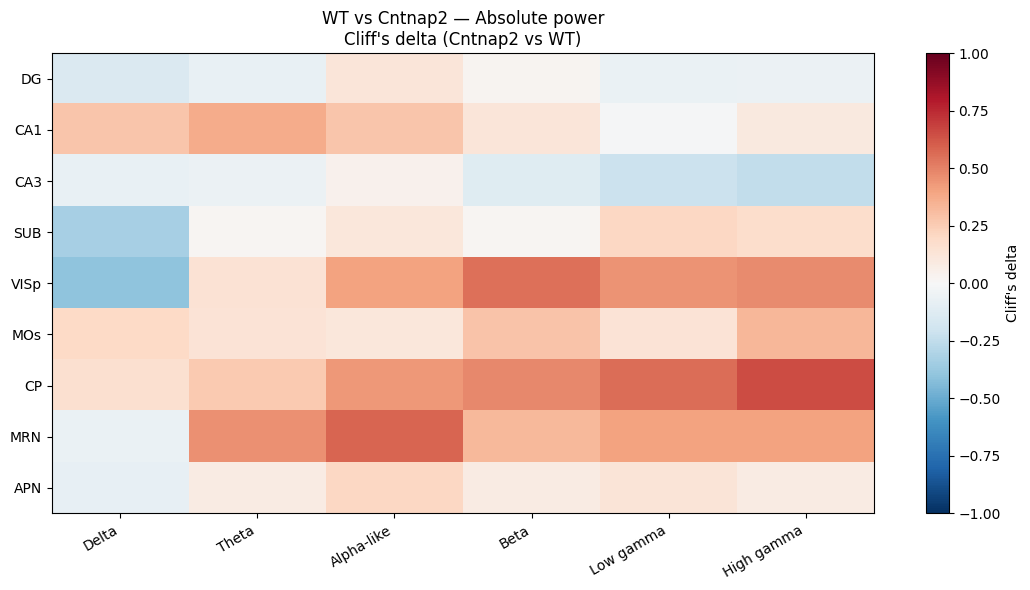

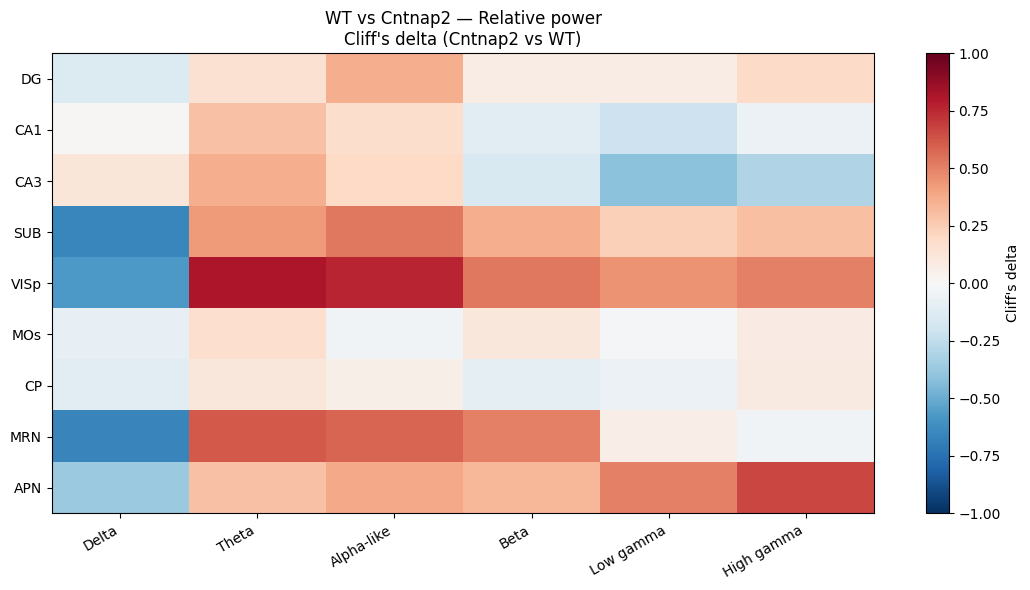

In [3]:

# ============================================================
# CELL 3 — WT vs CNTNAP2: EFFECT-SIZE HEATMAPS
# ============================================================

for metric, title, filename in [
    ("absolute_uv2", "Absolute power", "absolute"),
    ("relative_pct", "Relative power", "relative")
]:

    selected = results.loc[
        (results["metric"] == metric) &
        (results["analysis_level"] == "region")
    ]

    matrix = selected.pivot(
        index="region",
        columns="band",
        values="cliffs_delta_Cntnap2_vs_WT"
    ).reindex(
        index=REGIONS,
        columns=BANDS
    )

    fig, ax = plt.subplots(figsize=(11, 6))

    im = ax.imshow(
        matrix.values,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        aspect="auto"
    )

    ax.set_xticks(np.arange(len(BANDS)))
    ax.set_xticklabels(BANDS, rotation=30, ha="right")

    ax.set_yticks(np.arange(len(REGIONS)))
    ax.set_yticklabels(REGIONS)

    # Annotate significant comparisons.
    for i, region in enumerate(REGIONS):
        for j, band in enumerate(BANDS):

            hit = selected.loc[
                (selected.region == region) &
                (selected.band == band) &
                (selected.significant_FDR)
            ]

            if not hit.empty:
                ax.text(
                    j, i, "*",
                    ha="center",
                    va="center",
                    fontsize=17,
                    fontweight="bold",
                    color="black"
                )

    ax.set_title(
        f"WT vs Cntnap2 — {title}\n"
        "Cliff's delta (Cntnap2 vs WT)"
    )

    plt.colorbar(
        im,
        ax=ax,
        label="Cliff's delta"
    )

    plt.tight_layout()

    plt.savefig(
        OUT / f"heatmap_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


In [4]:

# Check raw and FDR-corrected significance

print("Total comparisons:", len(results))
print("Raw p < 0.05:", (results["p_raw"] < 0.05).sum())
print("FDR p < 0.05:", (results["p_FDR"] < 0.05).sum())

display(
    results.sort_values("p_raw")[
        [
            "region", "subregion", "band", "metric",
            "n_WT", "n_Cntnap2",
            "p_raw", "p_FDR",
            "cliffs_delta_Cntnap2_vs_WT"
        ]
    ].head(25)
)


Total comparisons: 312
Raw p < 0.05: 26
FDR p < 0.05: 1


,region,subregion,band,metric,n_WT,n_Cntnap2,p_raw,p_FDR,cliffs_delta_Cntnap2_vs_WT
108,MOs,MOs2/3,High gamma,absolute_uv2,10,8,0.000320,0.032634,0.925000
109,MOs,MOs2/3,Low gamma,absolute_uv2,10,8,0.002057,0.104895,0.825000
54,VISp,ALL,Theta,relative_pct,14,6,0.003302,0.174149,0.809524
110,MOs,MOs2/3,Beta,absolute_uv2,10,8,0.004388,0.149184,0.775000
55,VISp,ALL,Alpha-like,relative_pct,14,6,0.006450,0.174149,0.761905
217,VISp,VISp4,Theta,relative_pct,12,6,0.006895,0.449634,0.777778
111,MOs,MOs2/3,Theta,absolute_uv2,10,8,0.011655,0.297203,0.700000
112,MOs,MOs2/3,Alpha-like,absolute_uv2,10,8,0.015540,0.317016,0.675000
213,MRN,MRN,Delta,relative_pct,11,7,0.020425,0.449634,-0.662338
57,MRN,ALL,Delta,relative_pct,11,7,0.020425,0.340336,-0.662338


In [5]:

# Significance annotation:
# *  raw p < 0.05, but FDR >= 0.05
# ** FDR < 0.05

for i, region in enumerate(REGIONS):
    for j, band in enumerate(BANDS):

        hit = selected.loc[
            (selected.region == region) &
            (selected.band == band)
        ]

        if hit.empty:
            continue

        p_raw = float(hit.iloc[0]["p_raw"])
        p_fdr = float(hit.iloc[0]["p_FDR"])

        if p_fdr < 0.05:
            marker = "**"
        elif p_raw < 0.05:
            marker = "*"
        else:
            marker = ""

        if marker:
            ax.text(
                j, i, marker,
                ha="center",
                va="center",
                fontsize=15,
                fontweight="bold",
                color="black"
            )


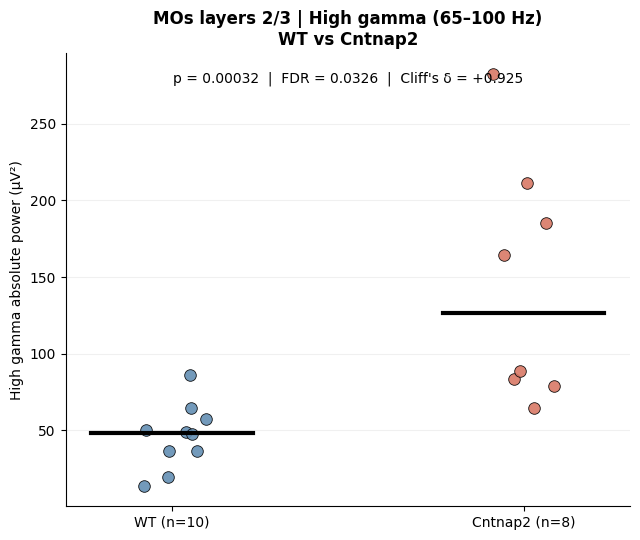

WT median: 48.40046666974621
Cntnap2 median: 126.65449807630318
Saved to: /content/drive/MyDrive/Reanalysis/Our_Analysis/lfp/spontaneous/genotype_comparison/WT_vs_Cntnap2/MOs2-3_HighGamma_WT_vs_Cntnap2.png


In [8]:

# ============================================================
# MOs2/3 — HIGH GAMMA ABSOLUTE POWER
# WT vs Cntnap2 | Individual animal-level data
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

REGION = "MOs"
SUBREGION = "MOs2/3"
BAND = "High gamma"
METRIC = "absolute_uv2"

column = f"{BAND}_{METRIC}"

subset = data.loc[
    (data["region"] == REGION) &
    (data["subregion"] == SUBREGION)
].copy()

wt_values = subset.loc[
    subset["genotype"] == "WT",
    column
].dropna().to_numpy(dtype=float)

cnt_values = subset.loc[
    subset["genotype"] == "Cntnap2",
    column
].dropna().to_numpy(dtype=float)

stat = results.loc[
    (results["region"] == REGION) &
    (results["subregion"] == SUBREGION) &
    (results["band"] == BAND) &
    (results["metric"] == METRIC)
].iloc[0]

p_raw = float(stat["p_raw"])
p_fdr = float(stat["p_FDR"])
delta = float(stat["cliffs_delta_Cntnap2_vs_WT"])

rng = np.random.default_rng(42)

fig, ax = plt.subplots(figsize=(6.5, 5.5))

for pos, values, label, color in [
    (0, wt_values, "WT", "#648fb4"),
    (1, cnt_values, "Cntnap2", "#d97966")
]:

    jitter = rng.uniform(-0.10, 0.10, len(values))

    ax.scatter(
        np.full(len(values), pos) + jitter,
        values,
        s=70,
        color=color,
        edgecolor="black",
        linewidth=0.6,
        alpha=0.9,
        zorder=3
    )

    median = np.median(values)

    ax.plot(
        [pos - 0.23, pos + 0.23],
        [median, median],
        color="black",
        linewidth=3,
        zorder=4
    )

ax.set_xticks([0, 1])
ax.set_xticklabels([
    f"WT (n={len(wt_values)})",
    f"Cntnap2 (n={len(cnt_values)})"
])

ax.set_ylabel("High gamma absolute power (µV²)")

ax.set_title(
    "MOs layers 2/3 | High gamma (65–100 Hz)\n"
    "WT vs Cntnap2",
    fontweight="bold"
)

ax.text(
    0.5, 0.96,
    f"p = {p_raw:.5f}  |  "
    f"FDR = {p_fdr:.4f}  |  "
    f"Cliff's δ = {delta:+.3f}",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10
)

ax.grid(axis="y", alpha=0.18)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

save_path = OUT / "MOs2-3_HighGamma_WT_vs_Cntnap2.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("WT median:", np.median(wt_values))
print("Cntnap2 median:", np.median(cnt_values))
print("Saved to:", save_path)


In [7]:

# All frequency bands in MOs2/3

mos = results.loc[
    (results["region"] == "MOs") &
    (results["subregion"] == "MOs2/3") &
    (results["metric"] == "absolute_uv2")
].copy()

mos["change_pct_median"] = (
    100 *
    (mos["Cntnap2_median"] - mos["WT_median"]) /
    mos["WT_median"]
)

display(
    mos[
        [
            "band",
            "WT_median",
            "Cntnap2_median",
            "change_pct_median",
            "p_raw",
            "p_FDR",
            "cliffs_delta_Cntnap2_vs_WT"
        ]
    ].sort_values("p_raw")
)


,band,WT_median,Cntnap2_median,change_pct_median,p_raw,p_FDR,cliffs_delta_Cntnap2_vs_WT
108,High gamma,48.400467,126.654498,161.680324,0.000320,0.032634,0.925
109,Low gamma,112.795239,334.171225,196.263591,0.002057,0.104895,0.825
110,Beta,303.247028,740.888160,144.318358,0.004388,0.149184,0.775
111,Theta,500.080212,1397.987786,179.552710,0.011655,0.297203,0.700
112,Alpha-like,203.239595,496.459981,144.273258,0.015540,0.317016,0.675
115,Delta,956.339794,2177.285778,127.668637,0.054527,0.617975,0.550
